# DNA Splicing Prediction using Deep Learning

In genomics, splice junctions are points on a DNA sequence wherein "superfluous" DNA is removed during the process of protein creation. This project aims to accurately classify DNA sequences into three categories (Intron-Exon boundaries, Exon-Intron boundaries, or neither) using the [Splice Junction Gene Sequences dataset](https://www.kaggle.com/datasets/muhammetvarl/splicejunction-gene-sequences-dataset/). 

We will start with a boilerplate neural network and improve our accuracy by introducing embedding layers, Convolutions, and callbacks.

In [16]:
"""
GENERAL IMPORTS
"""

import tensorflow as tf                                   #     for Keras
import pandas as pd                                       #     for data manipulation
import matplotlib.pyplot as plt                           #     for plotting
import seaborn as sns                                     #     for enhanced plotting
import numpy as np                                        #     for numerical operations

from sklearn.model_selection import train_test_split      #     creation of training and test sets
from sklearn.preprocessing import LabelEncoder            #     for encoding categorical labels

In [17]:
dataset_path = r"C:\Users\euanb\.cache\kagglehub\datasets\muhammetvarl\splicejunction-gene-sequences-dataset\versions\1\dna.csv"

## 1. Data Loading
Let's load the dataset and take a look at its structure. 

In [18]:
df = pd.read_csv(f"{dataset_path}")
display(df.head())

,A0,A1,A2,A3,A4,A5,A6,A7,A8,A9,...,A171,A172,A173,A174,A175,A176,A177,A178,A179,class
0,0,1,0,0,0,0,1,0,0,0,...,1,0,0,0,0,1,1,0,0,3
1,0,0,1,0,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,0,3
2,0,0,1,0,0,1,0,1,0,0,...,0,1,0,0,0,1,0,0,1,3
3,0,0,0,0,0,0,0,1,0,0,...,0,0,1,0,0,1,0,0,1,1
4,0,1,0,0,0,0,0,1,0,0,...,0,1,0,0,1,0,1,0,0,2


The dataset is in the form of 180 A_n x entries, where every 3 entries code for a single base.

The table of this encoding is shown below.

This gives us an actual length of 60 bases, or 180 As. 

| Base | A1 | A2 | A3 |
| - | - | - | - |
| A | 1 | 0 | 0 |
| C | 0 | 1 | 0 |
| G | 0 | 0 | 1 |
| T | 0 | 0 | 0 |

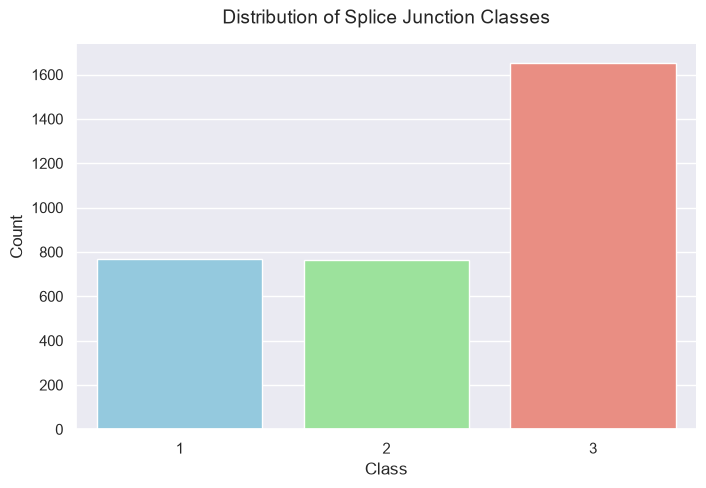

In [19]:
sns.set_theme(style="darkgrid",)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df, 
    x='class', 
    palette=['skyblue', 'lightgreen', 'salmon'],
    hue='class',
    legend=False
)

plt.title('Distribution of Splice Junction Classes', fontsize=14, pad=15)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Count', fontsize=12)

sns.despine()

plt.show()

We will now load the data into the X, and Y variables. 

In [20]:
X = df.drop(columns=["class"])
Y_b = df["class"]
Y = LabelEncoder().fit_transform(Y_b)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

## 2. Baseline Model
To establish a baseline, we will create a simple model with a single hidden layer.

In [21]:
model = tf.keras.Sequential(
    [
        tf.keras.layers.InputLayer(shape=(180,)),
        tf.keras.layers.Dense(64, activation="relu"),
    ]
)

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [22]:
history_baseline = model.fit(
    X_train, Y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

In [23]:
test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)
print(f"\nBaseline Test Accuracy: {test_acc * 100:.2f}%")


Baseline Test Accuracy: 94.51%


( This is suprisingly good for such a naive starting point )

## 3. Model with Embeddings and Convolutions
94% is a pretty good starting point, but we can squeeze out more accuracy by leveraging the sequential nature of DNA.


The first change is to introduce an embedding layer.


To prepare the original dataset for this, we need to reshape the data into DNA base pairs.


The transformation `np.dot(X_g, [1, 2, 3])` effectively converts encoded or separated sequential bases into single numerical tokens, which the Embedding layer can then project into a dense vector space.

In [24]:
df = pd.read_csv(f"{dataset_path}")

X_r = df.drop(columns=["class"]).values
X_g = X_r.reshape(-1, 60, 3)
X_c = np.dot(X_g, [1, 2, 3])

Y_b = df["class"]
Y = LabelEncoder().fit_transform(Y_b)

X_train, X_test, Y_train, Y_test = train_test_split(X_c, Y, test_size=0.2, random_state=42)

In [25]:
model_adv = tf.keras.Sequential(
    [
        tf.keras.layers.InputLayer(shape=(60,)),
        tf.keras.layers.Embedding(input_dim=4, output_dim=4),

        tf.keras.layers.Conv1D(filters=32, kernel_size=9, activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        
        tf.keras.layers.Conv1D(filters=64, kernel_size=9, activation='relu'),
        
        tf.keras.layers.Flatten(),

        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')
    ]
)

model_adv.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=["accuracy"]
)

## 4. Model Callbacks
To prevent overfitting and find the optimal weights, we implement `ReduceLROnPlateau` ( to dynamically lower the learning rate when validation accuracy stalls ) and `EarlyStopping` ( to halt training once the model stops improving and restore the best weights ).

In [ ]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_accuracy', 
    factor=0.5, 
    patience=3, 
    min_lr=0.00001
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', 
    patience=8, 
    restore_best_weights=True
)

In [27]:
history_final = model_adv.fit(
    X_train, Y_train,
    epochs=200,       
    batch_size=27,
    validation_split=0.2,
    callbacks=[reduce_lr, early_stop],
    verbose=0
)

test_loss, test_acc = model_adv.evaluate(X_test, Y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")


Final Test Accuracy: 96.08%


## 5. Training History & Conclusion

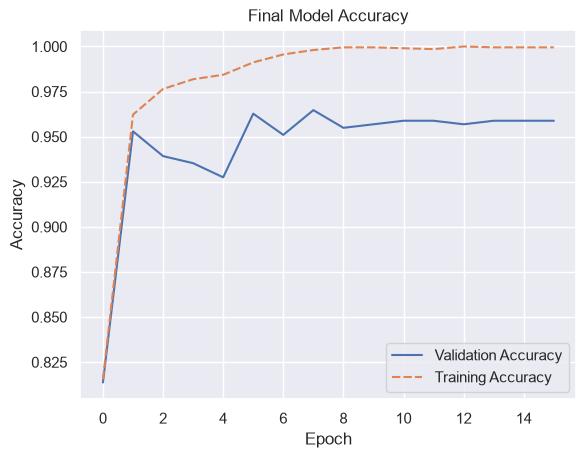

In [31]:
sns.set_theme(style="darkgrid")

history_df = pd.DataFrame({
    'Validation Accuracy': history_final.history['val_accuracy'],
    'Training Accuracy': history_final.history['accuracy'],
})

sns.lineplot(data=history_df)

plt.title('Final Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.show()

**Conclusion:**
By reframing the DNA data to allow for embeddings,  we successfully improved our model's capability to detect spatial patterns in the gene sequences; pushing up our accuracy of 94.51% up to a highly robust 96.39%, while reducing the risk of overfitting.

In [29]:
model_adv.save("splicing.keras")